# 01 Data preparation

**Goal.** Turn the raw class file (hourly prices of USATECH, a CFD on the Nasdaq-100) into two clean tables:

- `hourly.parquet`: every hourly bar, with returns and flags.
- `daily.parquet`: one row per trading day, closing at 16:00 New York, with VXN (implied vol) and the risk-free rate attached.

All logic lives in `src/data_prep.py`; this notebook only calls it and explains each step. Every assumption (file names, close hour, early-close dates, sample split) is read from `config.yaml`. The raw file is never modified, and only 1-hour and daily bars are built (hedging is daily).

In [1]:
import sys
sys.path.insert(0, "..")  # so `src` can be imported from the notebooks folder

import pandas as pd
from src import data_prep, plots
from src.config import load_config

pd.set_option("display.max_colwidth", 120, "display.width", 200)
cfg = load_config()

## Step 1. Load the class file

`load_hourly` reads the CSV, keeps the UTC timestamp as the index and adds two New York clock columns: when the bar opens (`time_ny`) and when it ends (`bar_end_ny`). New York time matters because the stock market's schedule is fixed in New York time, while its UTC hour shifts by one hour with daylight saving.

The `volume` column is renamed `tick_activity`: it is a vendor activity measure of unknown unit (almost every value is fractional, so it is not a count, and it falls about 10x over the sample), not traded volume, so it is never used.

In [2]:
bars = data_prep.load_hourly(cfg)
print(len(bars), "hourly bars")
bars.head()

29508 hourly bars


,open,high,low,close,tick_activity,time_ny,bar_end_ny
time_utc,,,,,,,
2020-07-01 04:00:00+00:00,10150.64,10154.29,10136.81,10139.77,2.83875,2020-07-01 00:00:00-04:00,2020-07-01 01:00:00-04:00
2020-07-01 05:00:00+00:00,10139.77,10143.73,10115.76,10126.67,6.18075,2020-07-01 01:00:00-04:00,2020-07-01 02:00:00-04:00
2020-07-01 06:00:00+00:00,10126.67,10151.08,10115.05,10147.68,6.22950,2020-07-01 02:00:00-04:00,2020-07-01 03:00:00-04:00
2020-07-01 07:00:00+00:00,10147.68,10167.12,10143.16,10152.45,5.49000,2020-07-01 03:00:00-04:00,2020-07-01 04:00:00-04:00
2020-07-01 08:00:00+00:00,10152.45,10163.06,10138.71,10147.00,5.07075,2020-07-01 04:00:00-04:00,2020-07-01 05:00:00-04:00


## Step 2. What does a timestamp mean? (open time or close time)

This decides which bar holds the 16:00 New York closing price, so it has to be settled before building daily bars.

**Finding: each bar is stamped with its OPEN time.** The bar stamped 15:00 covers 15:00 to 16:00, so *its close* is the 16:00 price. Three pieces of evidence:

1. **Activity by hour (table below, from the class file alone).** The average high-low range jumps at the bar stamped 09:00 (it contains the 09:30 stock-market open), stays high through 15:00 and collapses at 16:00. If stamps were close times, the bar stamped 16:00 would be the busy last hour of trading; instead its range drops by more than half, to overnight levels (58 bp at 15:00, 23 bp at 16:00).
2. **The daily pause.** The CFD is known to pause from 17:00 to 18:00 New York. No bar is ever stamped 17:00, and bars stamped 16:00 and 18:00 both exist. That only fits open-time stamps.
3. **Comparison with the official index close (outside check, run once during the analysis, not class data).** Against the official Nasdaq-100 daily close from Yahoo Finance, over the 1,246 days that have a bar stamped 15:00 New York (1,255 days once the 9 early closes are included), the close of that bar differs by 0.026% on average and its daily returns have correlation 0.9995. The bar stamped 16:00 is about 5 times worse (0.12%, correlation 0.979). A fixed UTC hour fails for half the year: only the New York-time rule works in both summer and winter.

So `daily_close_hour: 16` in `config.yaml` is the hour at which the closing bar **ends**.

In [3]:
data_prep.session_profile(bars).T.round(1)

hour_ny,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,18,19,20,21,22,23
bars,1292.0,1291.0,1290.0,1290.0,1291.0,1291.0,1291.0,1291.0,1290.0,1291.0,...,1255.0,1246.0,1246.0,1246.0,1290.0,1291.0,1291.0,1291.0,1291.0,1291.0
mean_range_bp,16.4,20.6,25.9,35.8,31.3,25.8,26.7,30.2,45.0,74.2,...,50.0,52.0,58.0,23.1,24.4,21.2,26.1,22.9,19.3,16.3


## Step 3. Hourly returns and gap flags

`add_returns_and_gaps` adds the hourly log return `ln(close / previous close)` and marks bars that do not follow the previous bar by exactly one hour:

- `after_closure`: the market was closed in between (the daily 17:00 pause, a weekend, a holiday). Normal.
- `after_data_gap`: bars are missing in the middle of a session (the vendor lost data). Only 3 cases, 4 bars.

Nothing is filled or interpolated. The flags exist so that nobody treats a return covering 2 or 50 hours as an ordinary one-hour return.

In [4]:
hourly = data_prep.add_returns_and_gaps(bars, cfg)
print(hourly[["after_closure", "after_data_gap"]].sum())
hourly.loc[hourly["after_data_gap"], ["time_ny", "gap_hours", "log_return"]]

after_closure     1291
after_data_gap       3
dtype: int64


,time_ny,gap_hours,log_return
time_utc,,,
2023-07-12 13:00:00+00:00,2023-07-12 09:00:00-04:00,2.0,0.009779
2024-07-19 08:00:00+00:00,2024-07-19 04:00:00-04:00,3.0,-0.006073
2024-12-17 16:00:00+00:00,2024-12-17 11:00:00-05:00,2.0,0.001463


## Step 4. Assign each bar to a trading day

The CFD trades about 23 hours a day from Sunday evening to Friday, but options and VXN live on the stock-market calendar. So a **trading day** here is everything between two stock-market closes:

> a bar belongs to the first trading day whose close is at or after the bar's end.

Consequences of this one rule:

- the bar stamped 15:00 (ending 16:00) is the last bar of its day;
- the bar stamped 16:00 and the evening bars belong to the *next* day;
- Sunday-evening bars fold into Monday (no Sunday "days");
- on a US holiday the CFD still trades a short session, but there is no stock-market close, so those bars fold into the next real trading day.

**Short days.** On 9 dates (day after Thanksgiving, Christmas Eve, 3 July) the stock market closed at 13:00. The bars cannot reveal this by themselves, so the dates are listed in `config.yaml` and the close on those days is the bar ending 13:00.

The example below shows a Friday close, the weekend, and Sunday evening already labelled as Monday.

In [5]:
hourly = data_prep.assign_trading_day(hourly, cfg)
hourly.loc["2021-07-16 18:00":"2021-07-18 23:00", ["time_ny", "close", "gap_hours", "after_closure", "trading_day"]]

,time_ny,close,gap_hours,after_closure,trading_day
time_utc,,,,,
2021-07-16 18:00:00+00:00,2021-07-16 14:00:00-04:00,14714.059,1.0,False,2021-07-16
2021-07-16 19:00:00+00:00,2021-07-16 15:00:00-04:00,14681.189,1.0,False,2021-07-16
2021-07-16 20:00:00+00:00,2021-07-16 16:00:00-04:00,14674.799,1.0,False,2021-07-19
2021-07-18 22:00:00+00:00,2021-07-18 18:00:00-04:00,14668.009,50.0,True,2021-07-19
2021-07-18 23:00:00+00:00,2021-07-18 19:00:00-04:00,14650.439,1.0,False,2021-07-19


## Step 5. Daily bars and realized variance

`build_daily` aggregates each trading day: open = first bar's open, high = highest high, low = lowest low, close = last bar's close.

**Careful with open, high and low.** The trading day starts right after the previous 16:00 close, so `open` is about equal to yesterday's close (it is *not* the 09:30 stock-market open), and `high`/`low` cover the evening, the night and any folded holiday session. They are wider than the official index range, so do not use them for an overnight gap or a range-based volatility estimate.

It also computes:

- `log_return`: close-to-close daily log return;
- `n_bars`: how many hourly bars the day holds (23 normally);
- `realized_var`: the sum of squared hourly log returns from the previous close to this close. It includes the returns across the 17:00 pause, weekends and folded holiday sessions (about 6.5% of the total), so it measures the same close-to-close move as the squared daily return. It is the input of the HAR-RV volatility forecast later.

The check below shows the daylight-saving handling: the close is always 16:00 in New York, which is 20:00 UTC in summer and 21:00 UTC in winter.

In [6]:
daily = data_prep.build_daily(hourly, cfg)
check = daily.loc[["2021-01-15", "2021-07-15", "2020-11-27"], ["close", "close_time_ny", "early_close", "n_bars"]]
check["close_time_utc"] = check["close_time_ny"].dt.tz_convert("UTC")
check

,close,close_time_ny,early_close,n_bars,close_time_utc
date,,,,,
2021-01-15,12806.189,2021-01-15 16:00:00-05:00,False,23,2021-01-15 21:00:00+00:00
2021-07-15,14797.259,2021-07-15 16:00:00-04:00,False,23,2021-07-15 20:00:00+00:00
2020-11-27,12260.109,2020-11-27 13:00:00-05:00,True,39,2020-11-27 18:00:00+00:00


In [7]:
daily.groupby(daily.index.year).size().rename("trading days per year").to_frame().T

date,2020,2021,2022,2023,2024,2025
trading days per year,128,252,251,250,252,122


## Step 6. Attach VXN, the interest rate and VIX (from FRED)

`merge_fred` adds, for each trading day, the latest FRED value dated **on or before** that day. It never takes a later value: that would be look-ahead (using information not yet known).

- `vxn_points` (25 = 25%) and `vxn_decimal` (0.25): the market's 30-day implied vol on the Nasdaq-100.
- `rate`: 3-month T-bill yield as a decimal, used as the risk-free rate.
- `vix_points`: for a comparison chart only.
- `*_stale_days`: how many calendar days old each value is (0 = same day).

VXN exists on every one of our trading days. The rate is missing on 9 days (Columbus Day and Veterans Day: bond market closed, stock market open) and is carried from the previous business day.

**Timing caveat.** VXN for day *t* is published a few minutes after the 16:00 close we trade at, and the same-day rate is also published after the close. "On or before that day" is therefore by date, not by clock time. The plan keeps VXN(t) as the baseline and tests "trade one day later" as a robustness check in the backtest phase; shifting the column one row gives a value strictly known at the close.

In [8]:
daily = data_prep.label_sample(data_prep.merge_fred(daily, data_prep.load_fred(cfg), cfg), cfg)
print(daily[["vxn_stale_days", "rate_stale_days", "vix_stale_days"]].max())
print(daily["sample"].value_counts())
daily.tail(3)

vxn_stale_days     0
rate_stale_days    3
vix_stale_days     0
dtype: int64
sample
in_sample        881
out_of_sample    374
Name: count, dtype: int64


,open,high,low,close,n_bars,close_time_ny,early_close,log_return,realized_var,vxn_points,vxn_stale_days,rate,rate_stale_days,vix_points,vix_stale_days,vxn_decimal,sample
date,,,,,,,,,,,,,,,,,
2025-06-26,22241.642,22470.798,22216.776,22450.689,23,2025-06-26 16:00:00-04:00,False,0.009317,0.000015,18.99,0,0.0439,0,16.59,0,0.1899,out_of_sample
2025-06-27,22450.197,22603.799,22383.109,22531.819,23,2025-06-27 16:00:00-04:00,False,0.003607,0.000102,18.89,0,0.0439,0,16.32,0,0.1889,out_of_sample
2025-06-30,22531.587,22716.299,22508.954,22669.665,23,2025-06-30 16:00:00-04:00,False,0.006099,0.000028,19.56,0,0.0441,0,16.73,0,0.1956,out_of_sample


`label_sample` (called in the same cell) tags each day `in_sample` or `out_of_sample` from the dates in `config.yaml`, so later phases cannot mix the two by accident.

## Step 7. Quality report

One row per check. Problems are **flagged and kept**, never deleted or silently fixed. In particular the 224 extreme hourly returns are real market moves (CPI releases, April 2025): they are exactly the tail risk a short-volatility strategy must survive, so they stay.

In [9]:
data_prep.quality_report(hourly, daily, data_prep.load_fred(cfg), cfg)

,check,count,detail,how_handled
0,hourly rows,29508,2020-07-01 04:00 to 2025-07-01 04:00 UTC,all rows kept
1,duplicate timestamps,0,,none found
2,timestamps out of order,0,,none found
3,missing values in price columns,0,,none found
4,zero or negative prices,0,,none found
5,OHLC inconsistencies,0,"high below open/close, or low above open/close",none found
6,flat bars (open = high = low = close),1,2023-02-20 18:00 UTC,kept
7,close equal to the previous bar's close,7,"2020-07-21 08:00, 2020-12-07 12:00, 2021-03-03 06:00, 2021-05-03 22:00, 2021-05-30 23:00, 2022-07-04 12:00, 2022-12-...",kept: gives a zero hourly return
8,open more than 10 bp from the previous close,12,largest 27 bp at 2023-11-29 14:00 UTC (back-to-back bars only),"kept: returns use closes only, so these do not enter any return"
9,bars outside the CFD session,0,"stamped 17:00 New York, on Saturday, or on Sunday before 18:00",none found: confirms stamps are bar-open times


## Step 8. Annualization factors

To turn a daily or hourly volatility into a yearly one we need the number of periods per year. These are counted from the data rather than assumed: the CFD trades about 23 hours a day, so the stock-market figure of 252 x 6.5 hours would be badly wrong for hourly bars.

In [10]:
factors = data_prep.annualization_factors(hourly, daily)
vol_from_daily = daily["log_return"].std() * factors["trading_days_per_year"] ** 0.5
vol_from_hourly = (daily["realized_var"].mean() * factors["trading_days_per_year"]) ** 0.5
print({k: round(v, 2) for k, v in factors.items()})
print(f"annualized vol from daily returns: {vol_from_daily:.1%}; from hourly realized variance: {vol_from_hourly:.1%}")

{'years_of_data': 5.0, 'trading_days_per_year': 251.03, 'hourly_bars_per_year': 5902.27}
annualized vol from daily returns: 23.4%; from hourly realized variance: 23.1%


The two volatility estimates agree (about 23%), which confirms that the hourly and daily tables are consistent.

## Step 9. Save everything

`main()` runs the same steps as above in one go and writes `data/processed/hourly.parquet`, `data/processed/daily.parquet`, and in `results/tables/`: `quality_report.csv`, `data_dictionary.csv`, `annualization.csv`. It is what `python -m src.data_prep` runs.

In [11]:
data_prep.main()
data_prep.data_dictionary()

hourly: 29508 bars, daily: 1255 trading days (2020-07-01 to 2025-06-30)
years_of_data: 5.00
trading_days_per_year: 251.03
hourly_bars_per_year: 5902.27


,column,table,unit,source,description
0,time_utc,hourly,UTC timestamp,class file,Bar open time (index).
1,open,hourly,index points,class file,First price of the hour.
2,high,hourly,index points,class file,Highest price of the hour.
3,low,hourly,index points,class file,Lowest price of the hour.
4,close,hourly,index points,class file,Last price of the hour.
5,tick_activity,hourly,vendor units,class file,"Raw 'volume' column: vendor activity measure of unknown unit, not traded volume. Not used."
6,time_ny,hourly,New York timestamp,derived,Bar open time in New York.
7,bar_end_ny,hourly,New York timestamp,derived,Bar open + 1 hour: the time at which 'close' was observed.
8,gap_hours,hourly,hours,derived,Time since the previous bar's open; 1 for back-to-back bars.
9,after_closure,hourly,true/false,derived,"First bar after a normal closure (daily pause, weekend, holiday)."


## Step 10. Sanity figure

Four panels to check the data by eye: the price path, hourly returns (orange = first bar after a closure, a different kind of return), VXN against VIX, and the number of hourly bars per trading day (23 normally; about 40 right after a holiday because the holiday session is folded in). Saved to `results/figures/data_sanity.png`.

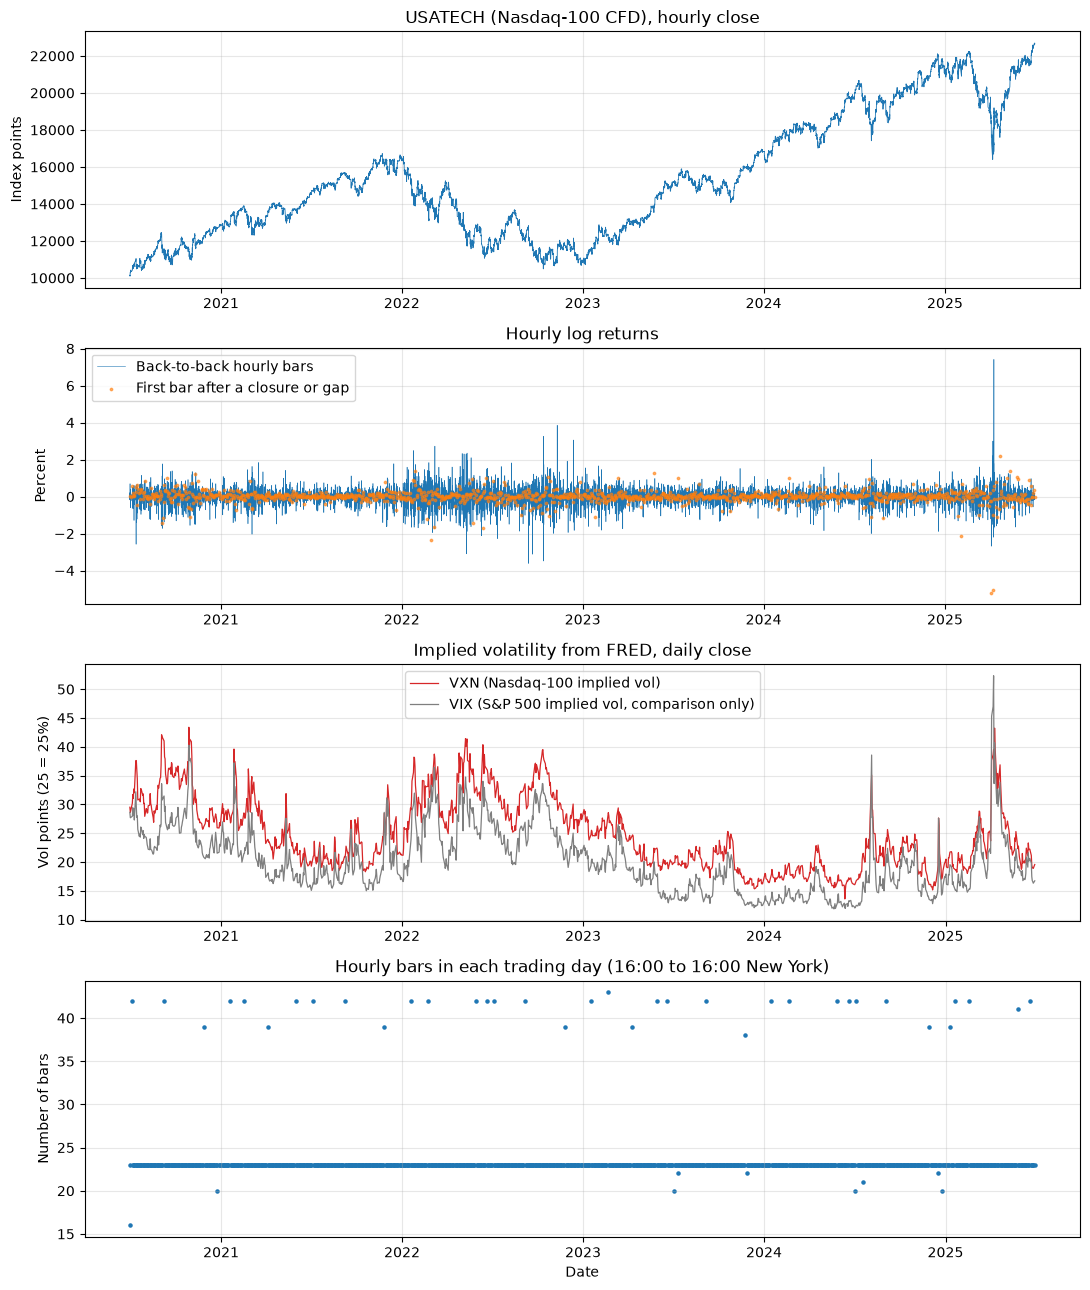

In [12]:
fig = plots.plot_data_sanity(hourly, daily)